In [1]:
import pandas as pd

products = pd.read_csv("product_info.csv")

products.head()

,product_id,product_name,brand_id,brand_name,loves_count,rating,reviews,size,variation_type,variation_value,...,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
0,P473671,Fragrance Discovery Set,6342,19-69,6320,3.6364,11.0,NaN,NaN,NaN,...,1,0,0,"['Unisex/ Genderless Scent', 'Warm &Spicy Scen...",Fragrance,Value & Gift Sets,Perfume Gift Sets,0,NaN,NaN
1,P473668,La Habana Eau de Parfum,6342,19-69,3827,4.1538,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,85.0,30.0
2,P473662,Rainbow Bar Eau de Parfum,6342,19-69,3253,4.2500,16.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0
3,P473660,Kasbah Eau de Parfum,6342,19-69,3018,4.4762,21.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0
4,P473658,Purple Haze Eau de Parfum,6342,19-69,2691,3.2308,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0


In [2]:
# Check column types and how many values are present.
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8494 entries, 0 to 8493
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_id          8494 non-null   object 
 1   product_name        8494 non-null   object 
 2   brand_id            8494 non-null   int64  
 3   brand_name          8494 non-null   object 
 4   loves_count         8494 non-null   int64  
 5   rating              8216 non-null   float64
 6   reviews             8216 non-null   float64
 7   size                6863 non-null   object 
 8   variation_type      7050 non-null   object 
 9   variation_value     6896 non-null   object 
 10  variation_desc      1250 non-null   object 
 11  ingredients         7549 non-null   object 
 12  price_usd           8494 non-null   float64
 13  value_price_usd     451 non-null    float64
 14  sale_price_usd      270 non-null    float64
 15  limited_edition     8494 non-null   int64  
 16  new   

In [3]:
# Count missing values in each column, highest first.
missing_values = products.isna().sum().sort_values(ascending=False)

missing_values[missing_values > 0]

,0
sale_price_usd,8224
value_price_usd,8043
variation_desc,7244
child_max_price,5740
child_min_price,5740
highlights,2207
size,1631
variation_value,1598
variation_type,1444
tertiary_category,990


In [4]:
# Check whether any complete rows appear more than once.
print("Duplicate rows:", products.duplicated().sum())

# Check whether product identifiers appear more than once.
print("Repeated product IDs:", products["product_id"].duplicated().sum())

Duplicate rows: 0
Repeated product IDs: 0


In [5]:
# Convert prices to numbers for inspection.
# Unreadable values become missing rather than causing an error.
price_check = pd.to_numeric(products["price_usd"], errors="coerce")

print("Missing or unreadable prices:", price_check.isna().sum())
print("Zero or negative prices:", (price_check <= 0).sum())

# Summarize the numeric prices.
price_check.describe()

Missing or unreadable prices: 0
Zero or negative prices: 0


,price_usd
count,8494.000000
mean,51.655595
std,53.669234
min,3.000000
25%,25.000000
50%,35.000000
75%,58.000000
max,1900.000000


In [6]:
# Inspect the five highest-priced listings.
products.nlargest(5, "price_usd")[
    ["product_name", "brand_name", "primary_category", "size", "price_usd"]
]

,product_name,brand_name,primary_category,size,price_usd
6802,Shani Darden by Déesse PRO LED Light Mask,Shani Darden Skin Care,Skincare,NaN,1900.0
5556,NuFACE Trinity+ & Effective Lip and Eye Attach...,NuFACE,Skincare,NaN,495.0
2162,DRx SpectraLite BodyWare Pro,Dr. Dennis Gross Skincare,Skincare,NaN,465.0
3510,Touch Home Permanent Hair Removal Device,iluminage,Skincare,NaN,449.0
5545,Trinity + Eye and Lip Enhancer Attachment Bundle,NuFACE,Skincare,NaN,449.0


In [7]:
# Display each primary category and its number of listings.
products["primary_category"].value_counts(dropna=False)

,count
primary_category,
Skincare,2420
Makeup,2369
Hair,1464
Fragrance,1432
Bath & Body,405
Mini Size,288
Men,60
Tools & Brushes,52
Gifts,4


In [8]:
# Find category labels with leading or trailing spaces.
categories = products["primary_category"]

space_issues = categories.ne(categories.str.strip())

print("Labels with extra spaces:", space_issues.sum())

Labels with extra spaces: 0


In [9]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

visuals_dir = Path("visuals")
visuals_dir.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [10]:
# Preserve the original uploaded data.
clean_products = products.copy()

text_columns = [
    "product_name",
    "brand_name",
    "primary_category",
    "secondary_category",
    "tertiary_category",
]

for column in text_columns:
    clean_products[column] = (
        clean_products[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

# Convert numeric fields without filling missing values with zero.
numeric_columns = [
    "price_usd",
    "sale_price_usd",
    "rating",
    "reviews",
]

for column in numeric_columns:
    clean_products[column] = pd.to_numeric(
        clean_products[column],
        errors="coerce"
    )

In [11]:
valid_price = (
    clean_products["price_usd"].notna()
    & np.isfinite(clean_products["price_usd"])
    & clean_products["price_usd"].gt(0)
)

print("Rows excluded for invalid prices:", (~valid_price).sum())

# The pricing table includes only finite, positive prices.
pricing = clean_products.loc[valid_price].copy()

invalid_rating = (
    pricing["rating"].notna()
    & ~pricing["rating"].between(1, 5)
)

print("Ratings outside the 1–5 range:", invalid_rating.sum())
print("Products available for pricing analysis:", len(pricing))

# Preserve missing categories as an explicit group if any exist.
pricing["primary_category"] = (
    pricing["primary_category"].fillna("Unknown")
)

Rows excluded for invalid prices: 0
Ratings outside the 1–5 range: 0
Products available for pricing analysis: 8494


In [12]:
overall_summary = (
    pricing["price_usd"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .rename("price_usd")
    .to_frame()
)

overall_summary.round(2)

,price_usd
count,8494.00
mean,51.66
median,35.00
min,3.00
max,1900.00
std,53.67


In [13]:
category_summary = (
    pricing.groupby("primary_category")
    .agg(
        product_count=("price_usd", "size"),
        mean_price=("price_usd", "mean"),
        median_price=("price_usd", "median"),
        min_price=("price_usd", "min"),
        max_price=("price_usd", "max"),
        std_price=("price_usd", "std"),
        q1_price=("price_usd", lambda prices: prices.quantile(0.25)),
        q3_price=("price_usd", lambda prices: prices.quantile(0.75)),
    )
)

category_summary["price_range"] = (
    category_summary["max_price"] - category_summary["min_price"]
)

category_summary["price_iqr"] = (
    category_summary["q3_price"] - category_summary["q1_price"]
)

category_summary = category_summary.sort_values(
    "mean_price",
    ascending=False
)

category_summary.round(2)

,product_count,mean_price,median_price,min_price,max_price,std_price,q1_price,q3_price,price_range,price_iqr
primary_category,,,,,,,,,,
Fragrance,1432,87.26,80.0,10.00,395.0,63.31,34.0,123.00,385.00,89.00
Skincare,2420,60.51,44.0,3.00,1900.0,69.75,28.0,70.00,1897.00,42.00
Gifts,4,50.00,50.0,50.00,50.0,0.00,50.0,50.00,0.00,0.00
Hair,1464,42.79,32.0,5.00,399.0,39.87,25.0,45.00,394.00,20.00
Bath & Body,405,42.23,38.0,3.00,300.0,28.73,25.0,50.00,297.00,25.00
Men,60,33.20,30.0,10.00,104.0,14.95,24.0,37.25,94.00,13.25
Makeup,2369,32.76,29.0,3.00,320.0,18.66,22.0,39.00,317.00,17.00
Tools & Brushes,52,31.92,19.5,4.95,249.0,44.75,12.0,25.25,244.05,13.25
Mini Size,288,21.40,18.0,3.00,165.0,13.74,15.0,24.00,162.00,9.00


In [14]:
MIN_CATEGORY_PRODUCTS = 10

eligible_categories = category_summary.loc[
    category_summary["product_count"] >= MIN_CATEGORY_PRODUCTS
]

category_extremes = pd.DataFrame({
    "comparison": [
        "Highest mean price",
        "Lowest mean price",
        "Highest median price",
        "Lowest median price",
    ],
    "category": [
        eligible_categories["mean_price"].idxmax(),
        eligible_categories["mean_price"].idxmin(),
        eligible_categories["median_price"].idxmax(),
        eligible_categories["median_price"].idxmin(),
    ],
    "price_usd": [
        eligible_categories["mean_price"].max(),
        eligible_categories["mean_price"].min(),
        eligible_categories["median_price"].max(),
        eligible_categories["median_price"].min(),
    ],
})

category_extremes.round(2)

,comparison,category,price_usd
0,Highest mean price,Fragrance,87.26
1,Lowest mean price,Mini Size,21.40
2,Highest median price,Fragrance,80.00
3,Lowest median price,Mini Size,18.00


In [15]:
MIN_BRAND_PRODUCTS = 10

brand_summary = (
    pricing.groupby("brand_name")
    .agg(
        product_count=("price_usd", "size"),
        mean_price=("price_usd", "mean"),
        median_price=("price_usd", "median"),
        min_price=("price_usd", "min"),
        max_price=("price_usd", "max"),
        category_count=("primary_category", "nunique"),
    )
)

eligible_brands = brand_summary.loc[
    brand_summary["product_count"] >= MIN_BRAND_PRODUCTS
].copy()

print("Brands meeting the minimum:", len(eligible_brands))

Brands meeting the minimum: 225


In [16]:
# Ten brands with the highest median listed prices.
eligible_brands.sort_values(
    ["median_price", "product_count"],
    ascending=[False, False]
).head(10).round(2)

,product_count,mean_price,median_price,min_price,max_price,category_count
brand_name,,,,,,
NuFACE,15,288.27,395.0,39.0,495.0,1
KILIAN Paris,29,193.45,230.0,30.0,340.0,1
ghd,19,191.74,205.0,28.0,399.0,2
La Mer,39,197.95,190.0,25.0,425.0,4
Augustinus Bader,19,173.37,180.0,57.0,390.0,4
The Maker,10,132.50,175.0,35.0,175.0,1
SK-II,16,186.44,170.0,75.0,400.0,1
T3,26,131.03,160.0,25.0,249.0,2
Bio Ionic,13,163.92,159.0,24.0,299.0,1


In [17]:
# Ten brands with the lowest median listed prices.
eligible_brands.sort_values(
    ["median_price", "product_count"],
    ascending=[True, False]
).head(10).round(2)

,product_count,mean_price,median_price,min_price,max_price,category_count
brand_name,,,,,,
The Ordinary,54,12.43,10.00,5.00,40.7,4
INC.redible,16,13.69,12.00,10.00,25.0,3
The INKEY List,47,13.55,12.99,5.99,27.0,2
SEPHORA COLLECTION,352,16.38,14.50,3.00,85.0,8
NAILS INC.,25,17.06,15.00,8.99,37.5,1
Mario Badescu,42,18.48,18.00,5.00,49.0,2
LYS Beauty,12,18.67,19.00,12.00,24.0,1
PATTERN by Tracee Ellis Ross,48,18.15,20.00,7.00,35.0,2
Verb,44,23.07,20.00,20.00,70.0,2


In [18]:
q1 = pricing["price_usd"].quantile(0.25)
q3 = pricing["price_usd"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

pricing["overall_price_outlier"] = (
    pricing["price_usd"].lt(lower_bound)
    | pricing["price_usd"].gt(upper_bound)
)

print(f"Overall lower boundary: ${lower_bound:.2f}")
print(f"Overall upper boundary: ${upper_bound:.2f}")
print("Flagged listings:", pricing["overall_price_outlier"].sum())
print(
    "Flagged percentage:",
    f"{pricing['overall_price_outlier'].mean():.1%}"
)

Overall lower boundary: $-24.50
Overall upper boundary: $107.50
Flagged listings: 845
Flagged percentage: 9.9%


In [19]:
# Also flag unusual prices within each category.
category_groups = pricing.groupby("primary_category")["price_usd"]

category_q1 = category_groups.transform(
    lambda prices: prices.quantile(0.25)
)
category_q3 = category_groups.transform(
    lambda prices: prices.quantile(0.75)
)
category_iqr = category_q3 - category_q1
category_size = category_groups.transform("size")

# Avoid applying this rule to categories with fewer than 10 listings.
pricing["category_price_outlier"] = (
    pricing["price_usd"].lt(category_q1 - 1.5 * category_iqr)
    | pricing["price_usd"].gt(category_q3 + 1.5 * category_iqr)
).astype("boolean")

pricing.loc[
    category_size < MIN_CATEGORY_PRODUCTS,
    "category_price_outlier"
] = pd.NA

pricing.loc[
    pricing["overall_price_outlier"],
    [
        "product_name",
        "brand_name",
        "primary_category",
        "price_usd",
        "category_price_outlier",
    ]
].sort_values("price_usd", ascending=False).head(15)

,product_name,brand_name,primary_category,price_usd,category_price_outlier
6802,Shani Darden by Déesse PRO LED Light Mask,Shani Darden Skin Care,Skincare,1900.0,True
5556,NuFACE Trinity+ & Effective Lip and Eye Attach...,NuFACE,Skincare,495.0,True
2162,DRx SpectraLite BodyWare Pro,Dr. Dennis Gross Skincare,Skincare,465.0,True
3510,Touch Home Permanent Hair Removal Device,iluminage,Skincare,449.0,True
5551,Trinity Facial Toning Device + Wrinkle Reducer...,NuFACE,Skincare,449.0,True
5545,Trinity + Eye and Lip Enhancer Attachment Bundle,NuFACE,Skincare,449.0,True
5546,Trinity + Eye and Lip Enhancer Attachment Bundle,NuFACE,Skincare,429.0,True
5553,Trinity Facial Toning Device + Wrinkle Reducer...,NuFACE,Skincare,429.0,True
4313,The Concentrate Serum,La Mer,Skincare,425.0,True
4320,The Regenerating Serum,La Mer,Skincare,410.0,True


In [20]:
tier_order = ["Affordable", "Mid-range", "Premium"]

pricing["price_tier"] = pd.cut(
    pricing["price_usd"],
    bins=[0, 25, 60, np.inf],
    labels=tier_order,
    right=False,
)

tier_summary = (
    pricing["price_tier"]
    .value_counts(sort=False)
    .reindex(tier_order, fill_value=0)
    .rename_axis("price_tier")
    .to_frame("product_count")
)

tier_summary["percentage"] = (
    tier_summary["product_count"] / len(pricing) * 100
)

print("Affordable: under $25")
print("Mid-range: $25 to under $60")
print("Premium: $60 or more")

tier_summary.round(2)

Affordable: under $25
Mid-range: $25 to under $60
Premium: $60 or more


,product_count,percentage
price_tier,,
Affordable,2020,23.78
Mid-range,4427,52.12
Premium,2047,24.10


In [21]:
category_tier_percent = pd.crosstab(
    pricing["primary_category"],
    pricing["price_tier"],
    normalize="index",
).reindex(columns=tier_order, fill_value=0).mul(100)

category_tier_percent.round(1)

price_tier,Affordable,Mid-range,Premium
primary_category,,,
Bath & Body,24.0,56.0,20.0
Fragrance,5.1,38.6,56.3
Gifts,0.0,100.0,0.0
Hair,22.3,65.0,12.7
Makeup,32.3,62.0,5.7
Men,28.3,65.0,6.7
Mini Size,75.7,22.2,2.1
Skincare,20.0,46.0,34.0
Tools & Brushes,73.1,15.4,11.5


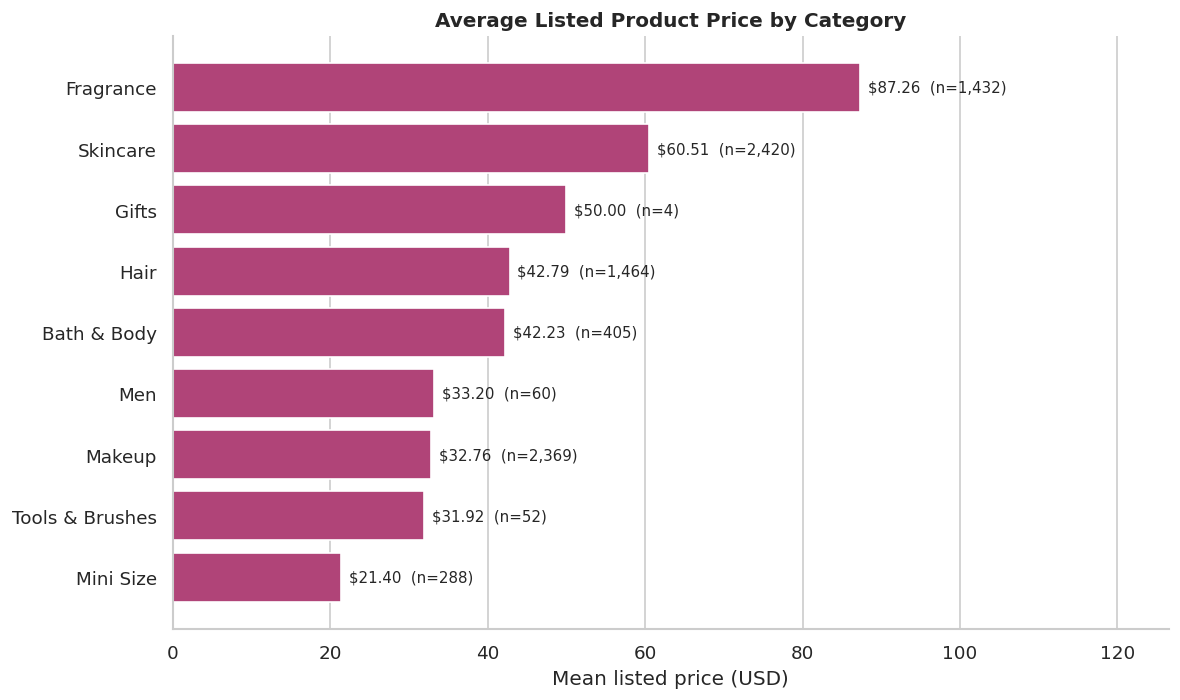

In [22]:
plot_data = category_summary.sort_values("mean_price")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data.index,
    plot_data["mean_price"],
    color="#B04478",
)

for position, (_, row) in enumerate(plot_data.iterrows()):
    ax.text(
        row["mean_price"] + 1,
        position,
        f"${row['mean_price']:.2f}  (n={int(row['product_count']):,})",
        va="center",
        fontsize=9,
    )

ax.set_title("Average Listed Product Price by Category")
ax.set_xlabel("Mean listed price (USD)")
ax.set_ylabel("")
ax.set_xlim(0, plot_data["mean_price"].max() * 1.45)
ax.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig(
    visuals_dir / "average_price_by_category.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

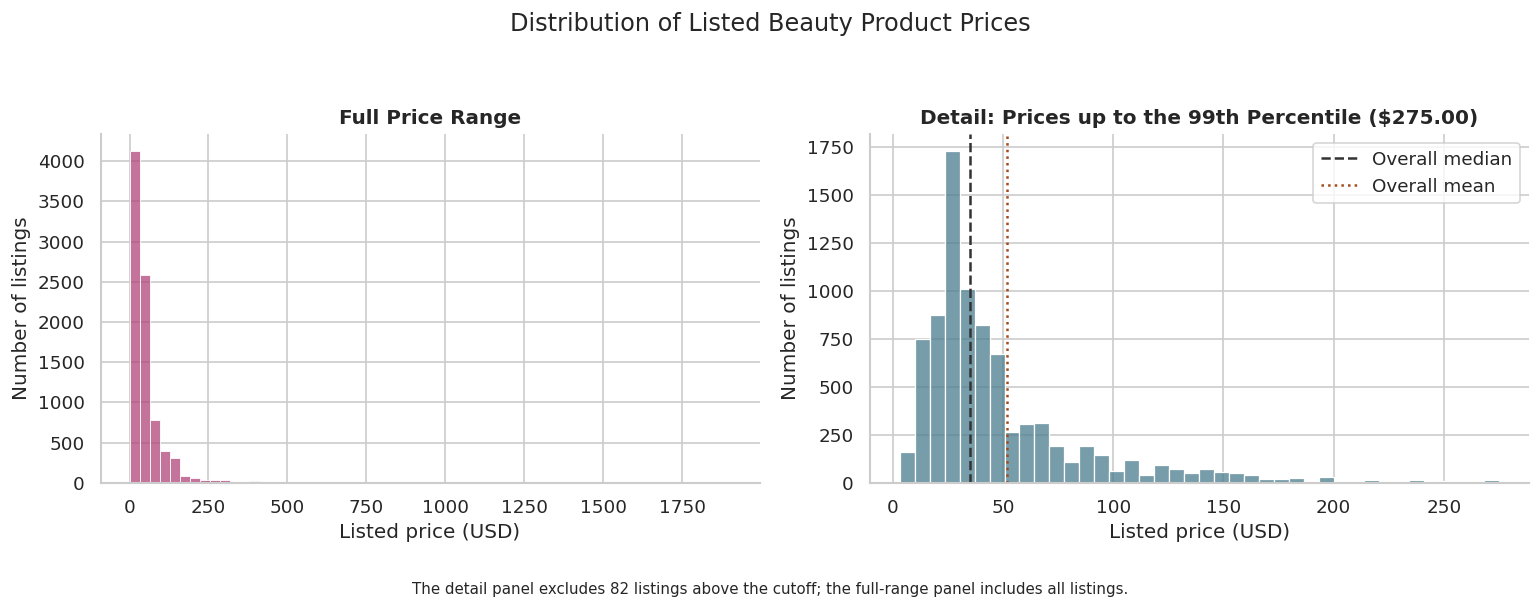

In [23]:
p99 = pricing["price_usd"].quantile(0.99)
zoom_prices = pricing.loc[
    pricing["price_usd"] <= p99,
    "price_usd"
]
above_zoom = pricing["price_usd"].gt(p99).sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=pricing,
    x="price_usd",
    bins=60,
    color="#B04478",
    ax=axes[0],
)
axes[0].set_title("Full Price Range")

sns.histplot(
    x=zoom_prices,
    bins=40,
    color="#497D8E",
    ax=axes[1],
)
axes[1].axvline(
    pricing["price_usd"].median(),
    color="#333333",
    linestyle="--",
    label="Overall median",
)
axes[1].axvline(
    pricing["price_usd"].mean(),
    color="#A34B19",
    linestyle=":",
    label="Overall mean",
)
axes[1].set_title(
    f"Detail: Prices up to the 99th Percentile (${p99:.2f})"
)
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Listed price (USD)")
    ax.set_ylabel("Number of listings")

fig.suptitle("Distribution of Listed Beauty Product Prices")
fig.text(
    0.5,
    0.01,
    f"The detail panel excludes {above_zoom:,} listings above the cutoff; "
    "the full-range panel includes all listings.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.06, 1, 0.93])
fig.savefig(
    visuals_dir / "price_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

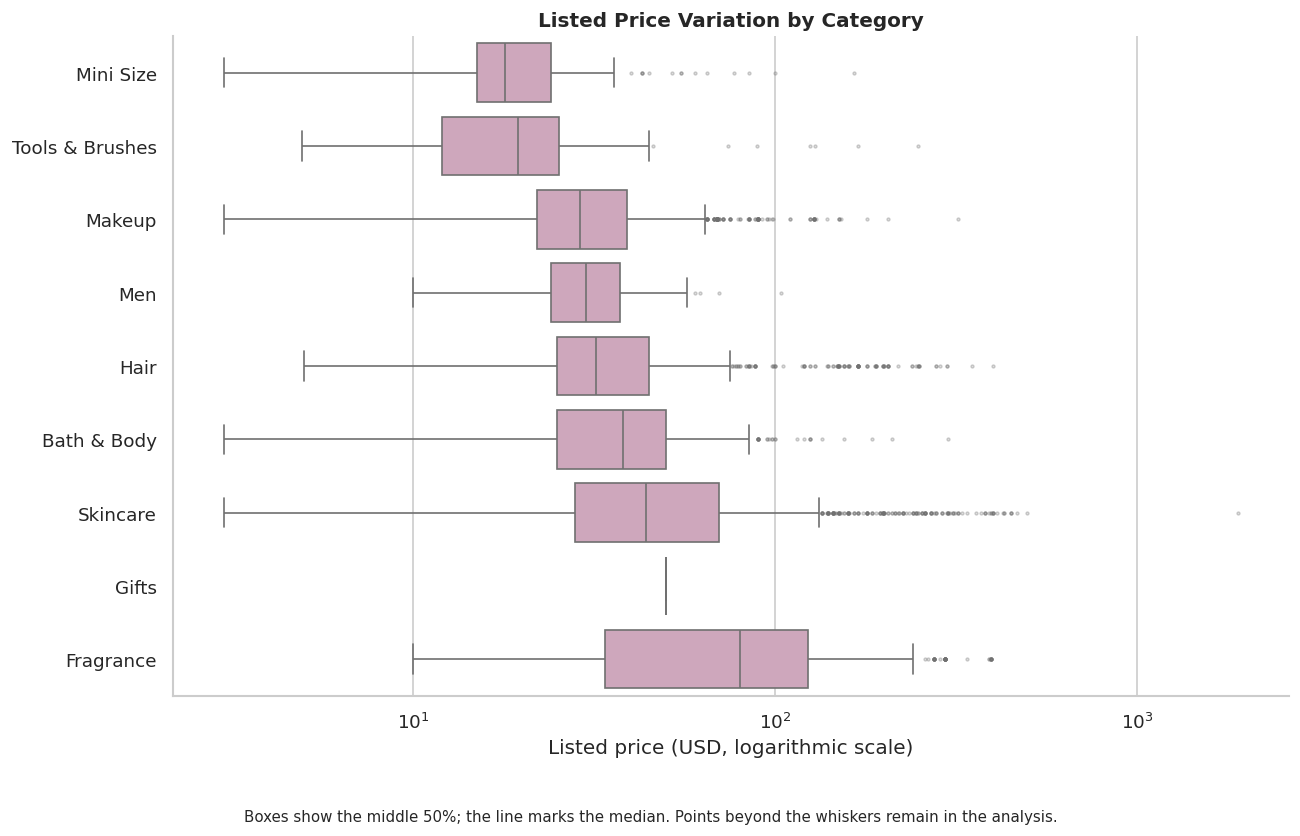

In [24]:
category_order = (
    category_summary.sort_values("median_price").index.tolist()
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.boxplot(
    data=pricing,
    x="price_usd",
    y="primary_category",
    order=category_order,
    color="#D5A0BD",
    showfliers=True,
    flierprops={
        "marker": ".",
        "markersize": 3,
        "alpha": 0.4,
    },
    ax=ax,
)

ax.set_xscale("log")
ax.set_title("Listed Price Variation by Category")
ax.set_xlabel("Listed price (USD, logarithmic scale)")
ax.set_ylabel("")

fig.text(
    0.5,
    0.01,
    "Boxes show the middle 50%; the line marks the median. "
    "Points beyond the whiskers remain in the analysis.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(
    visuals_dir / "price_variation_by_category.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

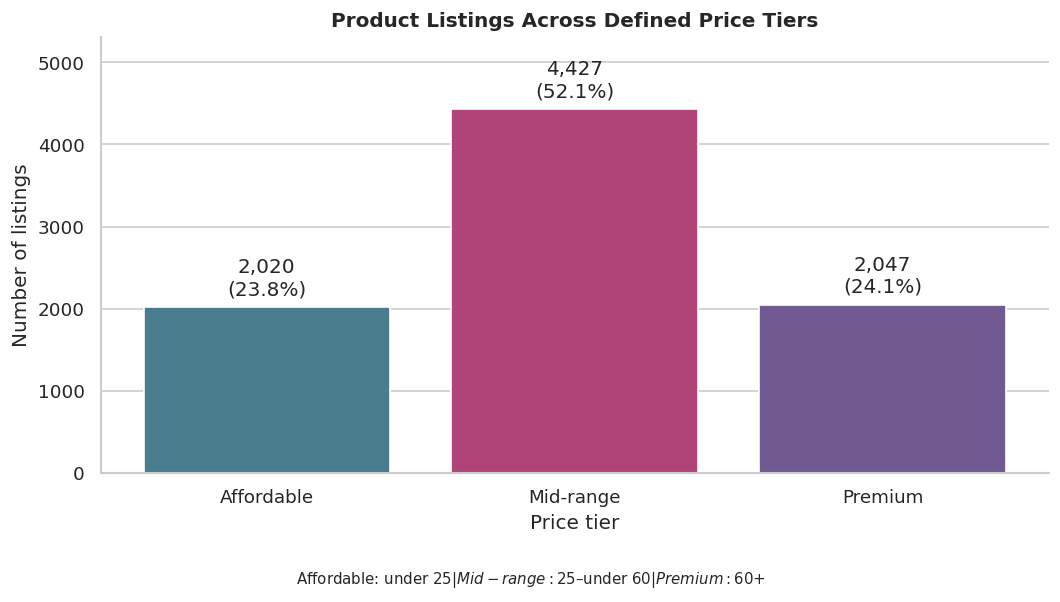

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    tier_summary.index,
    tier_summary["product_count"],
    color=["#497D8E", "#B04478", "#705A91"],
)

for bar, (_, row) in zip(bars, tier_summary.iterrows()):
    ax.annotate(
        f"{int(row['product_count']):,}\n({row['percentage']:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )

ax.set_title("Product Listings Across Defined Price Tiers")
ax.set_xlabel("Price tier")
ax.set_ylabel("Number of listings")
ax.set_ylim(0, tier_summary["product_count"].max() * 1.2)
ax.grid(axis="x", visible=False)

fig.text(
    0.5,
    0.01,
    "Affordable: under $25 | Mid-range: $25–under $60 | Premium: $60+",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(
    visuals_dir / "price_tier_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [26]:
rating_data = pricing.loc[
    pricing["rating"].between(1, 5),
    ["price_usd", "rating", "reviews", "primary_category"],
].copy()

print("Listings included:", len(rating_data))
print("Listings excluded:", len(pricing) - len(rating_data))

# Pearson measures linear association.
pearson_r = rating_data["price_usd"].corr(rating_data["rating"])

# Correlating ranks gives Spearman correlation without an extra library.
spearman_r = (
    rating_data["price_usd"].rank()
    .corr(rating_data["rating"].rank())
)

pd.Series({
    "Pearson correlation": pearson_r,
    "Spearman correlation": spearman_r,
}).round(3)

Listings included: 8216
Listings excluded: 278


,0
Pearson correlation,0.057
Spearman correlation,0.149


In [27]:
# Check whether the association changes when requiring more reviews.
MIN_REVIEWS = 10

review_supported = rating_data.loc[
    rating_data["reviews"] >= MIN_REVIEWS
]

pd.Series({
    "Listings with at least 10 reviews": len(review_supported),
    "Pearson correlation": (
        review_supported["price_usd"]
        .corr(review_supported["rating"])
    ),
    "Spearman correlation": (
        review_supported["price_usd"].rank()
        .corr(review_supported["rating"].rank())
    ),
}).round(3)

,0
Listings with at least 10 reviews,7165.000
Pearson correlation,0.083
Spearman correlation,0.163


In [28]:
output_dir = Path("analysis_outputs")
output_dir.mkdir(exist_ok=True)

pricing.to_csv(output_dir / "cleaned_product_pricing.csv", index=False)

category_summary.to_csv(output_dir / "category_price_summary.csv")
eligible_brands.to_csv(output_dir / "brand_price_summary.csv")
tier_summary.to_csv(output_dir / "price_tier_summary.csv")

print("Saved analysis tables:")
for path in sorted(output_dir.glob("*.csv")):
    print(path.name)

print("\nSaved charts:")
for path in sorted(visuals_dir.glob("*.png")):
    print(path.name)

Saved analysis tables:
brand_price_summary.csv
category_price_summary.csv
cleaned_product_pricing.csv
price_tier_summary.csv

Saved charts:
average_price_by_category.png
price_distribution.png
price_tier_distribution.png
price_variation_by_category.png


In [29]:
import shutil
from google.colab import files

shutil.make_archive("beauty_pricing_visuals", "zip", visuals_dir)
files.download("beauty_pricing_visuals.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>